# Improve conditional diffusion model performance

In the last notebook, we introduced a conditional diffusion model; however, the model does not always generate the samples we want. 

In this notebook, we replace our simple U-Net with a U-Net that has attention in it.

The training dataset is the same. We first train the attention-based U-Net, examine its performance, and then elaborate more on why the two architectures perform so differently.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

from funs.SineWave_Dataset import SineWave_Random_DataSet
from funs.plotting import plot_batched_lines
from funs.scheduler import (
    add_noise_from_zero,
    add_noise_onestep_cum_sampler,
    ddpm_sampler,
    noise_scheduler,
)
from funs.time_embedding import get_sinusoidal_table
from funs.unet_1d import UNet1D
from funs.unet_1d_attention import AttentionUNet1D

torch.manual_seed(7)
plt.rcParams["figure.figsize"] = (5, 3)

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

Using device: cuda


## Model specification
We specify the two models as `model_simple` and `model_atten`. The former is the simpler U-Net we use in the previous notebook.

`model_atten` is the one that has attention in it and has position embedding injected within it (Lines 24 and 29 in `unet_1d_attention.py`). 

Since training was done previously, we can simply load the model weights for the simple U-Net, and train the attention-based U-Net in the later cells.

It is worth noting that the only difference in specifying the two designs is that the attention-based U-Net has an input **num_heads = 4**. This input is required as it adopts a multi-head self-attention in its bottleneck.

In [12]:
# Define parameters and datasets

freq_max = 10

dataset = SineWave_Random_DataSet(freq_max=freq_max, n_dim=200, random_bias = True, random_phase=False)
data_loader = DataLoader(dataset, batch_size=64, shuffle=True)

T = 500
schedule = noise_scheduler(T=T)

Adopting a linear scheduler


We make cases for the 2 UNet designs, and apply one dummy sample to `model_atten` to check the shape of the output

In [13]:
model_simple = UNet1D(
    in_channels=1,
    base_channels=64,
    t_steps=500,
    t_dim=64,
    cond_dim=1,
    emb_dim=72,
)

model_atten = AttentionUNet1D(
    num_heads = 4,
    in_channels=1,
    base_channels=64,
    t_steps=500,
    t_dim=64,
    cond_dim=1,
    emb_dim=72,
    
)

dummy_x_t = torch.randn(12, 1, 200)
dummy_t = torch.randint(0, T, (12,))
dummy_c = torch.randn(12, 1)

model_atten.eval()
with torch.no_grad():
    dummy_prediction_atten = model_atten(dummy_x_t, dummy_t, dummy_c)
    
assert dummy_prediction_atten.shape == dummy_x_t.shape
print("model input: ", tuple(dummy_x_t.shape))
print("model output:", tuple(dummy_prediction_atten.shape))



model input:  (12, 1, 200)
model output: (12, 1, 200)


## Training
The training code here is identical to that in the previous notebook, except that we swap **`model`** with **`model_atten`**.

In [15]:
TRAIN_MODEL = True
EPOCHS = 100
weights_path = Path("trained_parameters/attention_conditional.pt")

model_atten = model_atten.to(device)
schedule_device = {name: values.to(device) for name, values in schedule.items()}

if TRAIN_MODEL:
    loss_fn = nn.MSELoss()
    optimizer = optim.AdamW(model_atten.parameters(), lr=5e-4)
    model_atten.train()

    for epoch_index in range(EPOCHS):
        running_loss = 0.0

        for batch_index, (x_label_batch, x_clean_batch, _, _) in enumerate(data_loader):
            x_clean_batch = x_clean_batch.to(device)
            x_label_batch = x_label_batch.to(device)
            x_label_batch = x_label_batch/freq_max  ### Normalization is lazily done here
            t_batch = torch.randint(
                0,
                T,
                (x_clean_batch.shape[0],),
                device=device,
            )

            x_t_batch, target_noise = add_noise_from_zero(
                x_clean_batch,
                t_batch,
                schedule_device,
                device,
            )
            x_t_batch = x_t_batch.unsqueeze(1)
            target_noise = target_noise.unsqueeze(1)

            optimizer.zero_grad()
            predicted_noise = model_atten(x_t_batch, t_batch, x_label_batch)
            loss = loss_fn(predicted_noise, target_noise)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        mean_loss = running_loss / len(data_loader)
        print(f"epoch {epoch_index + 1:02d}: mean loss={mean_loss:.6f}")

    torch.save(model_atten.state_dict(), weights_path)

else:
    state_dict = torch.load(weights_path, map_location=device, weights_only=True)
    model_atten.load_state_dict(state_dict)
    print(f"Loaded pretrained weights from {weights_path}.")

model_atten.eval()

epoch 01: mean loss=0.009742
epoch 02: mean loss=0.008914
epoch 03: mean loss=0.009102
epoch 04: mean loss=0.009105
epoch 05: mean loss=0.009020
epoch 06: mean loss=0.008865
epoch 07: mean loss=0.009360
epoch 08: mean loss=0.009000
epoch 09: mean loss=0.008935
epoch 10: mean loss=0.008983
epoch 11: mean loss=0.008895
epoch 12: mean loss=0.009688
epoch 13: mean loss=0.008823
epoch 14: mean loss=0.008669
epoch 15: mean loss=0.008785
epoch 16: mean loss=0.008277
epoch 17: mean loss=0.008672
epoch 18: mean loss=0.008689
epoch 19: mean loss=0.008825
epoch 20: mean loss=0.008959
epoch 21: mean loss=0.008603
epoch 22: mean loss=0.008667
epoch 23: mean loss=0.008687
epoch 24: mean loss=0.008686
epoch 25: mean loss=0.008695
epoch 26: mean loss=0.008880
epoch 27: mean loss=0.008671
epoch 28: mean loss=0.008621
epoch 29: mean loss=0.008843
epoch 30: mean loss=0.008760
epoch 31: mean loss=0.008543
epoch 32: mean loss=0.008378
epoch 33: mean loss=0.008343
epoch 34: mean loss=0.008421
epoch 35: mean

AttentionUNet1D(
  (cond_embed): ConditionEmbedding(
    (time_proj): Sequential(
      (0): Linear(in_features=64, out_features=72, bias=True)
      (1): SiLU()
      (2): Linear(in_features=72, out_features=72, bias=True)
    )
    (cond_proj): Sequential(
      (0): Linear(in_features=1, out_features=72, bias=True)
      (1): SiLU()
      (2): Linear(in_features=72, out_features=72, bias=True)
    )
  )
  (in_conv): Conv1d(1, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (down1): ResBlock1D_conditional(
    (conv1): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (conv2): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
    (norm2): GroupNorm(8, 64, eps=1e-05, affine=True)
    (act): SiLU()
    (emb_proj): Linear(in_features=72, out_features=64, bias=True)
    (skip): Identity()
  )
  (pool1): Conv1d(64, 128, kernel_size=(4,), stride=(2,), padding=(1,))
  (down2): ResBlock1D_conditional(
    (conv1

Let's also load the weights of the simple U-Net

In [5]:
weights_path = Path("trained_parameters/conditional_unet.pt")

state_dict = torch.load(weights_path, map_location=device, weights_only=True)
model_simple.load_state_dict(state_dict)
print(f"Loaded pretrained weights from {weights_path}.")
model_simple = model_simple.to(device)
model_simple.eval()

Loaded pretrained weights from trained_parameters/conditional_unet.pt.


UNet1D(
  (cond_embed): ConditionEmbedding(
    (time_proj): Sequential(
      (0): Linear(in_features=64, out_features=72, bias=True)
      (1): SiLU()
      (2): Linear(in_features=72, out_features=72, bias=True)
    )
    (cond_proj): Sequential(
      (0): Linear(in_features=1, out_features=72, bias=True)
      (1): SiLU()
      (2): Linear(in_features=72, out_features=72, bias=True)
    )
  )
  (in_conv): Conv1d(1, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (down1): ResBlock1D_conditional(
    (conv1): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (conv2): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (norm1): GroupNorm(8, 64, eps=1e-05, affine=True)
    (norm2): GroupNorm(8, 64, eps=1e-05, affine=True)
    (act): SiLU()
    (emb_proj): Linear(in_features=72, out_features=64, bias=True)
    (skip): Identity()
  )
  (pool1): Conv1d(64, 128, kernel_size=(4,), stride=(2,), padding=(1,))
  (down2): ResBlock1D_conditional(
    (conv1): Conv1d

## Generation
Following the previous notebook, we generate the samples and examine them using the trained `model_simple` and `model_atten`. 

In [6]:
torch.manual_seed(30)

freqs = [1.0, 1.5, 2.0, 4.0, 6.0, 7.5, 9.0, 12.0, 16.0]
generated_list_simple = []
generated_list_atten = []

truth_list_simple = []
truth_list_atten = []

coord = torch.linspace(0, 2 * torch.pi,  200)

for freq in freqs:
    generated_list_simple.append(
        ddpm_sampler(sample_dim=200, n_sample=4, noise_dict=schedule_device,
            cond = (torch.tensor([freq, freq, freq, freq])/freq_max).to(device),
    model=model_simple,
    device=device,
        )
    )

    generated_list_atten.append(
        ddpm_sampler(sample_dim=200, n_sample=4, noise_dict=schedule_device,
            cond = (torch.tensor([freq, freq, freq, freq])/freq_max).to(device),
    model=model_atten,
    device=device,
        )
    )

    truth_list_simple.append(torch.sin(coord * freq))
    truth_list_atten.append(torch.sin(coord * freq))


Let's view the results from the U-Net with attention

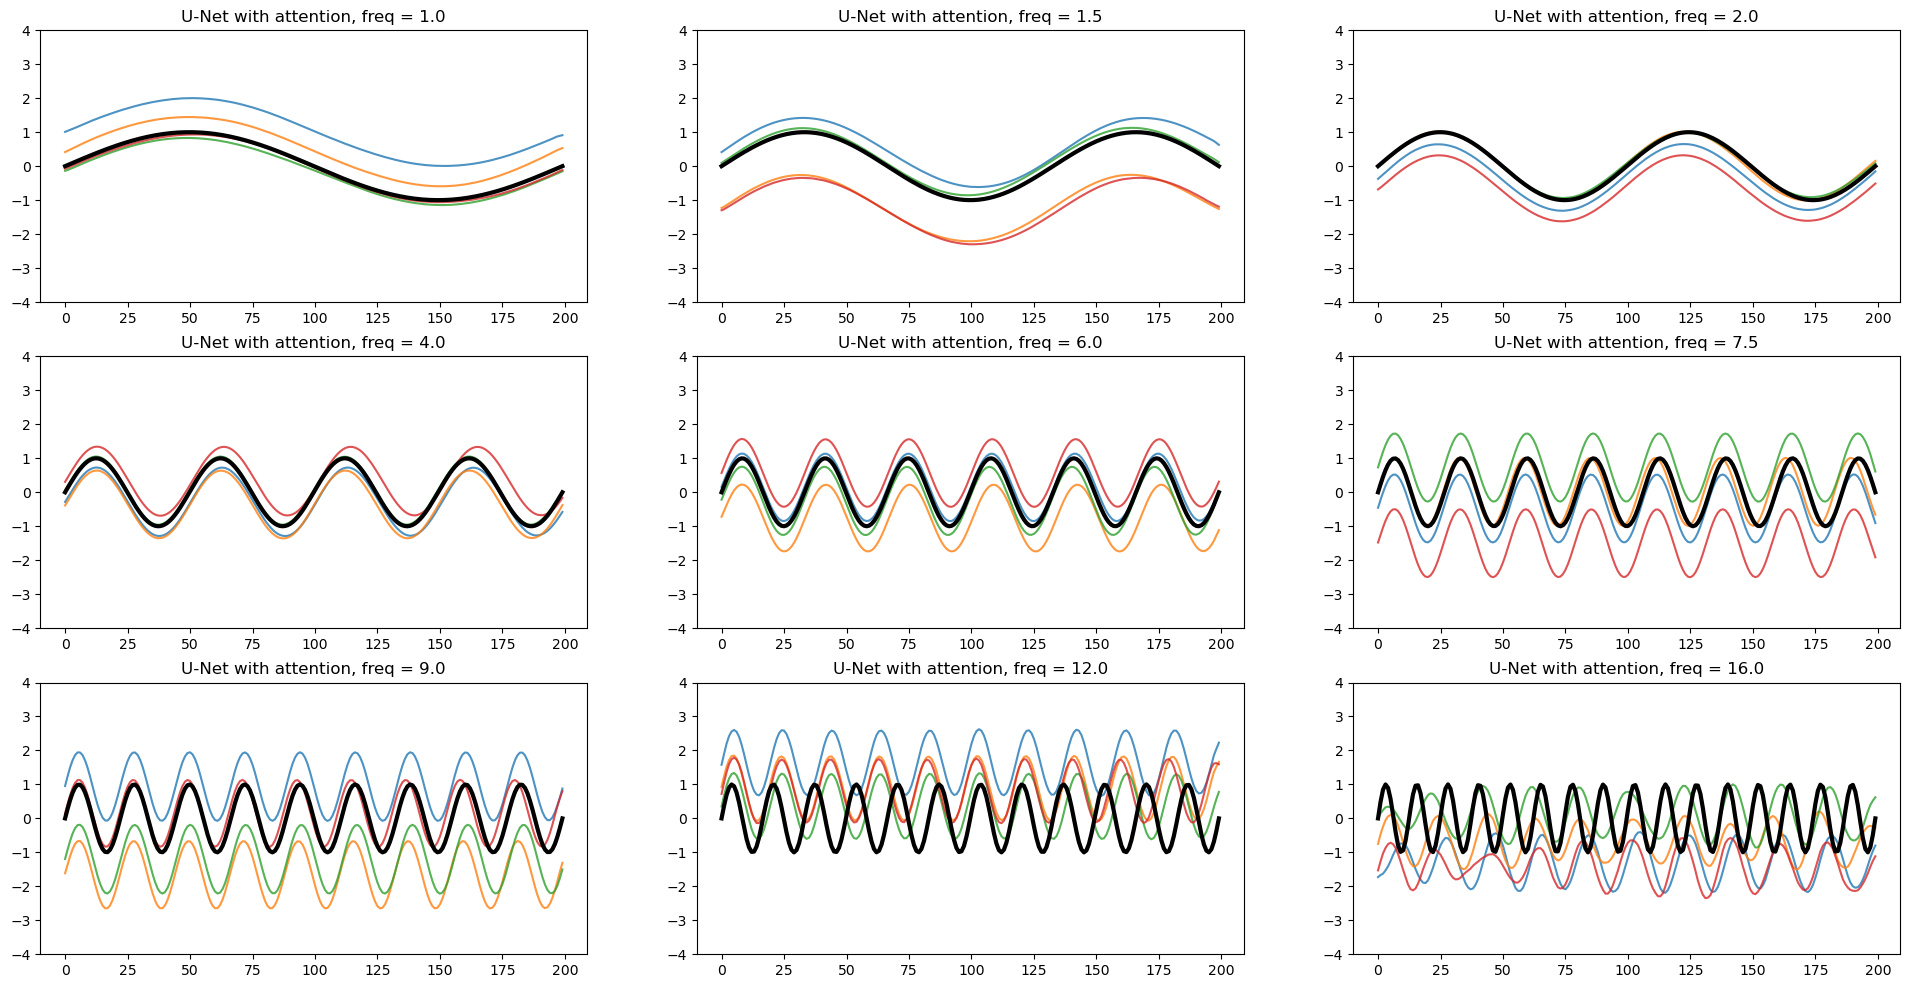

In [7]:
fig, axs = plt.subplots(3, 3, figsize=(24, 12))
axs = axs.ravel()

for ax, generated, truth, freq in zip(axs, generated_list_atten, truth_list_atten, freqs):
    for sample in generated:
        ax.plot(sample[0].detach().cpu(), alpha = 0.8)

    ax.plot(truth, linewidth=3, color = "black")
    ax.set_title(f"U-Net with attention, freq = {freq}")
    ax.set_ylim(-4, 4)

Following the previous notebook, we can examine the generated samples with the bias/offset removed, and compare them with the ``real`` sine curves. Their differences are also plotted below.

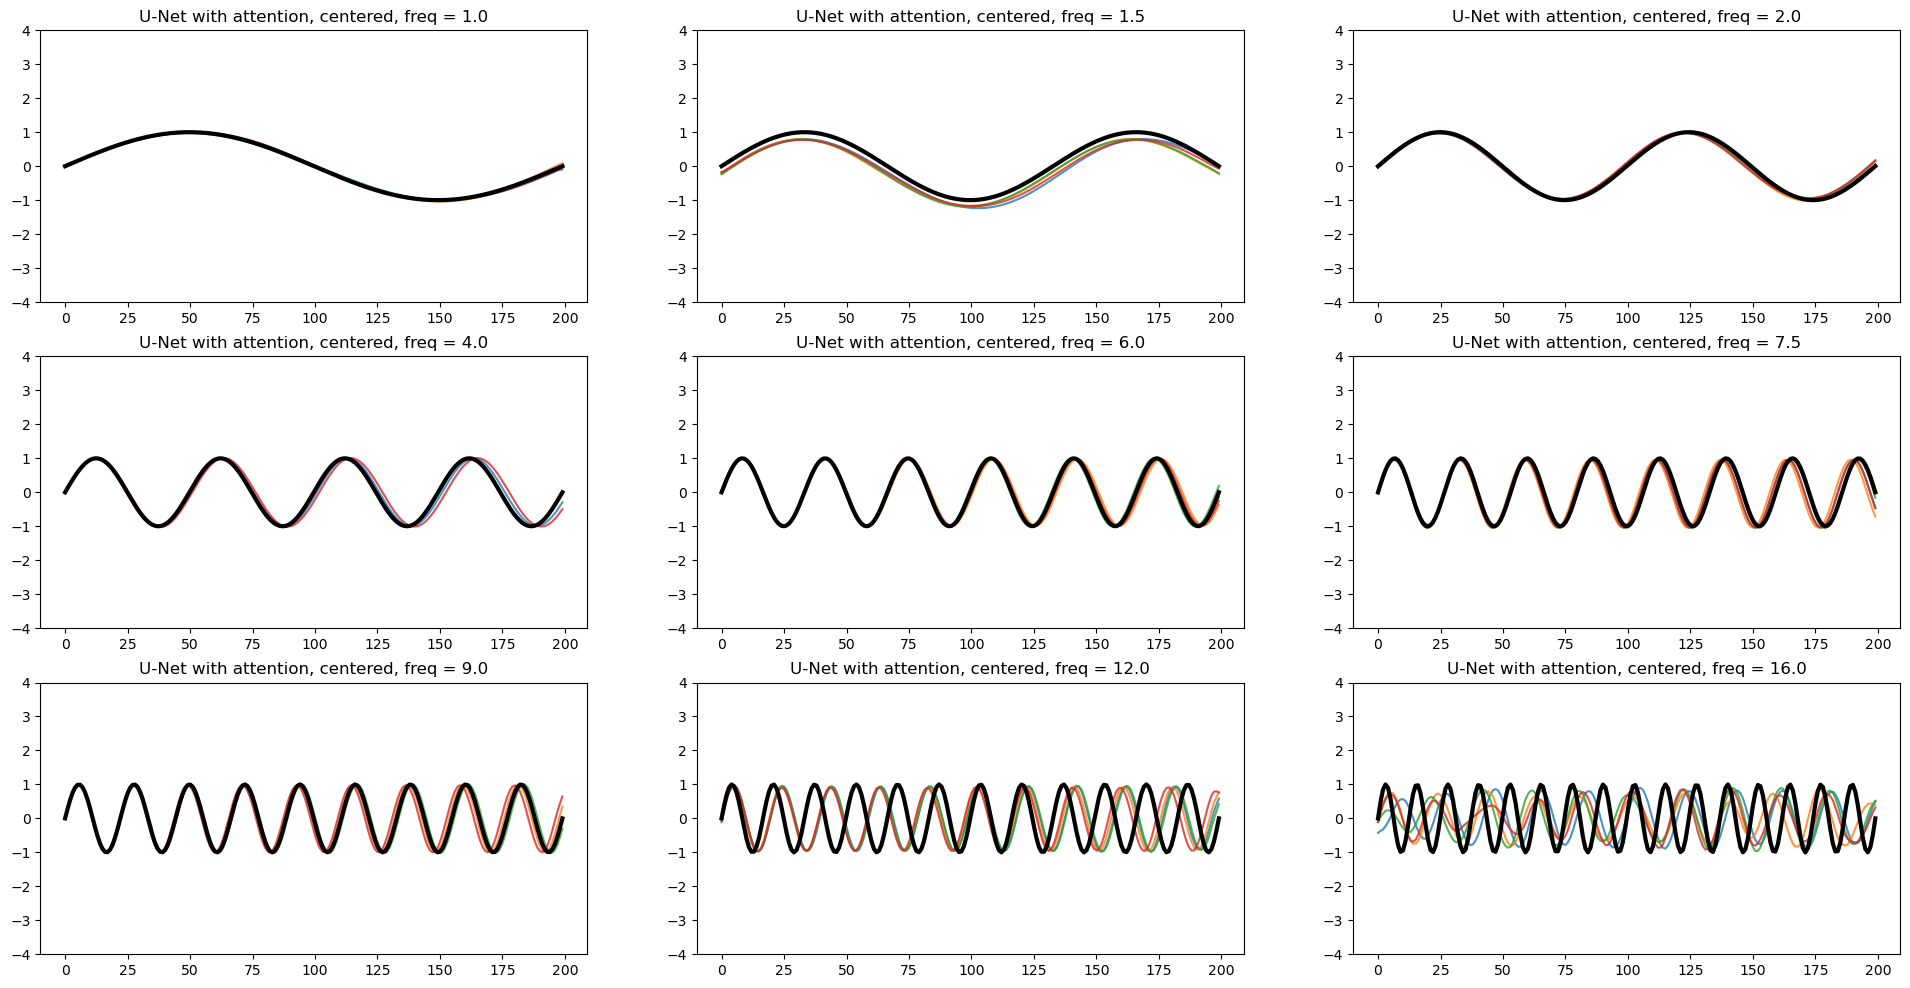

In [16]:
fig, axs = plt.subplots(3, 3, figsize=(24, 12))
axs = axs.ravel()

for ax, generated, truth, freq in zip(axs, generated_list_atten, truth_list_atten, freqs):
    for sample in generated:
        sample = sample[0].detach().cpu()
        sample = sample - sample.mean()
        
        ax.plot(sample, alpha = 0.8)

    ax.plot(truth, linewidth=3, color = "black")
    ax.set_title(f"U-Net with attention, centered, freq = {freq}")
    ax.set_ylim(-4, 4)

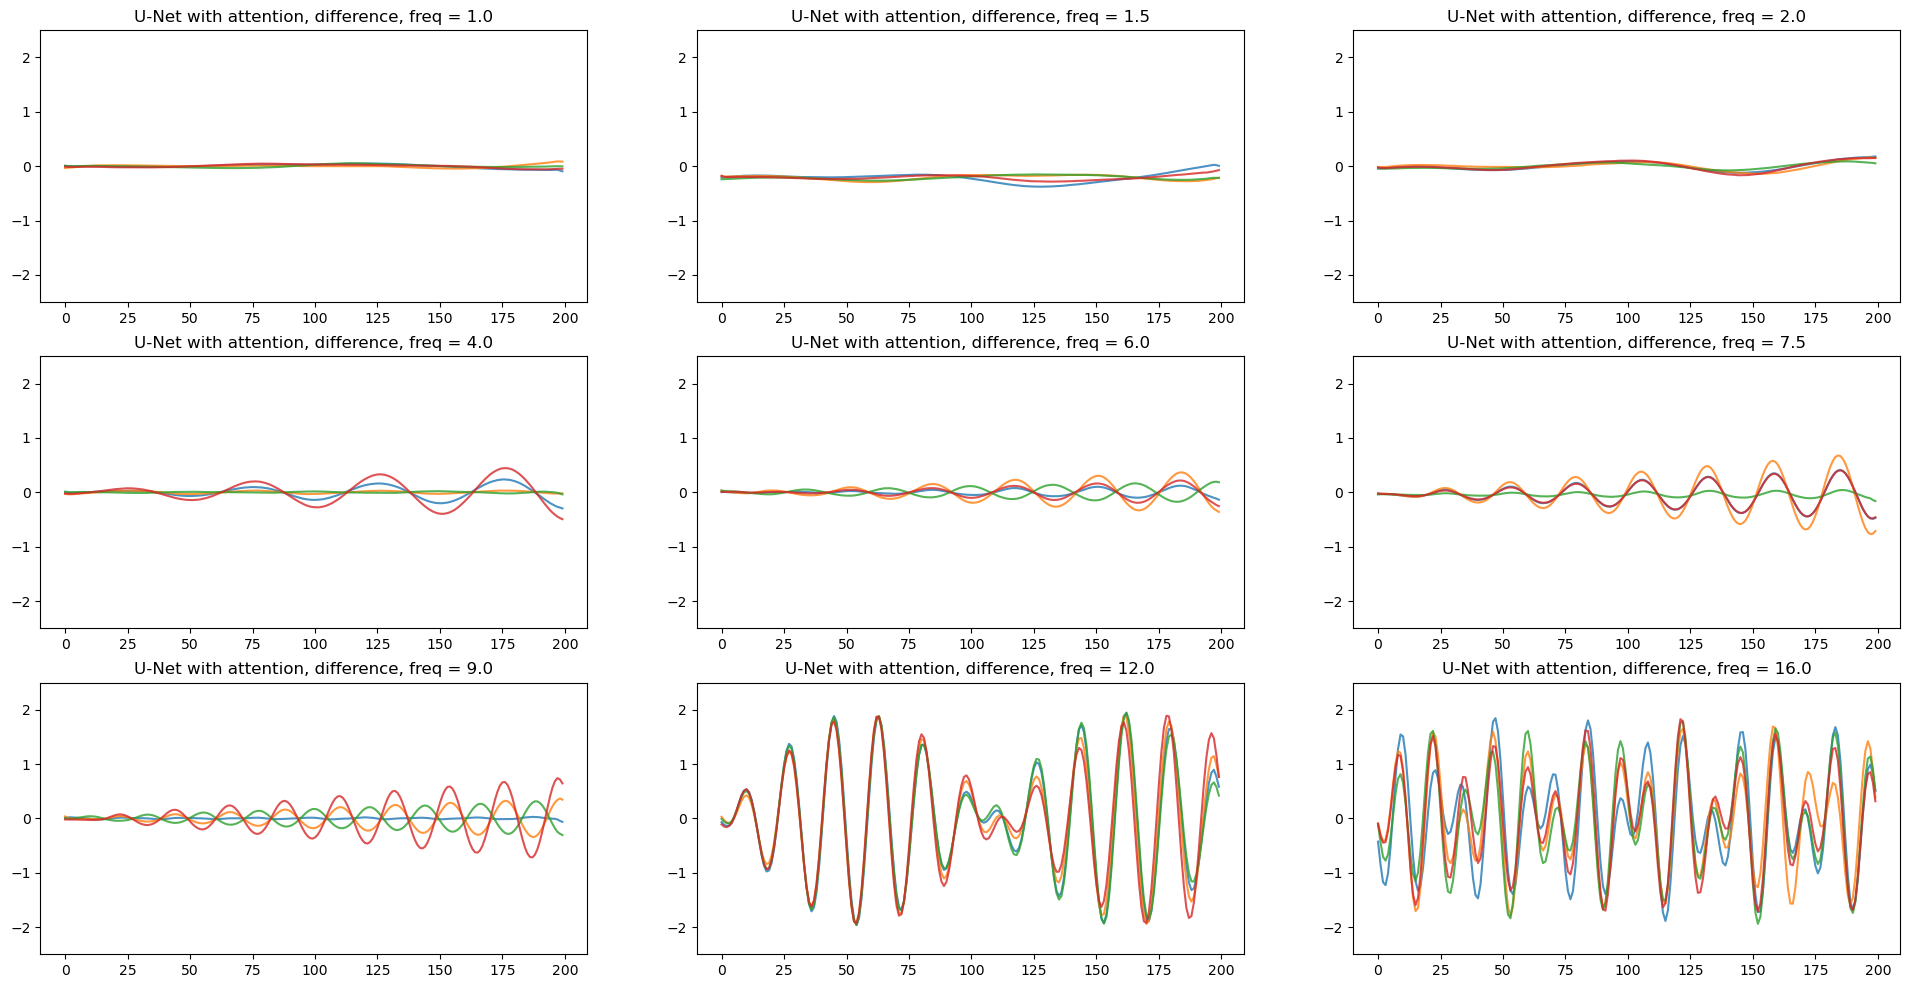

In [17]:
fig, axs = plt.subplots(3, 3, figsize=(24, 12))
axs = axs.ravel()

for ax, generated, truth, freq in zip(axs, generated_list_atten, truth_list_atten, freqs):
    for sample in generated:
        sample = sample[0].detach().cpu()
        sample = sample - sample.mean()
        
        ax.plot(sample - truth, alpha = 0.8)

    ax.set_title(f"U-Net with attention, difference, freq = {freq}")
    ax.set_ylim(-2.5, 2.5)

For comparison, here is the same difference plot for the simple U-Net (``model_simple``) from the previous notebook. Both models were trained on the same data with the same training loop; the generated curves above and below come from the same generation cell.

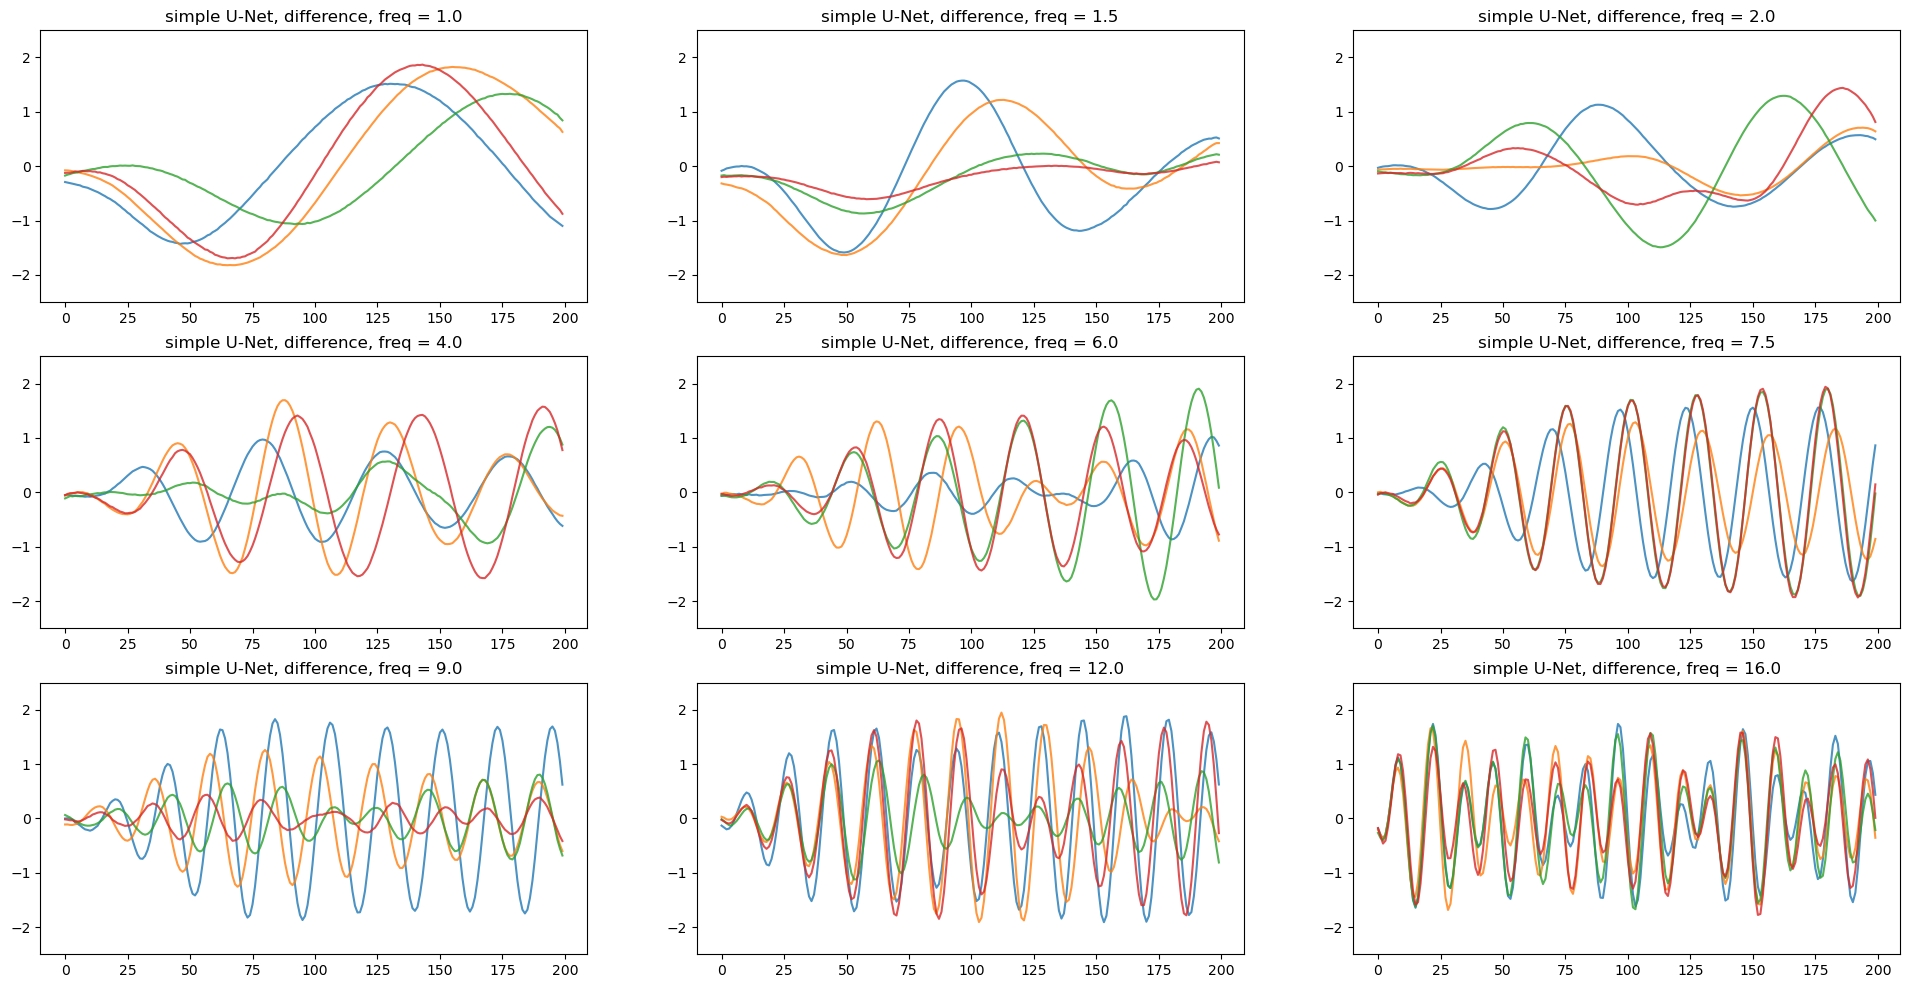

In [18]:
fig, axs = plt.subplots(3, 3, figsize=(24, 12))
axs = axs.ravel()

for ax, generated, truth, freq in zip(axs, generated_list_simple, truth_list_simple, freqs):
    for sample in generated:
        sample = sample[0].detach().cpu()
        sample = sample - sample.mean()

        ax.plot(sample - truth, alpha = 0.8)

    ax.set_title(f"simple U-Net, difference, freq = {freq}")
    ax.set_ylim(-2.5, 2.5)

## Summary of the above results
Compared with the simple U-Net, the U-Net with attention follows the requested sine waves much more closely.

What is left is a small difference that is close to zero at the left end and grows toward the right end. It is easiest to see at the higher frequencies, where a curve (the differences) has many cycles. 

Below we first explain why the difference grows along x, and **then unpack how the two U-Nets differ**.

## Why does the difference grow along x?

In the difference plot of the U-Net with attention, at the higher frequencies the difference is close to zero at the left end and gets larger toward the right end. This does **not** mean that the frequency of a generated curve changes along x. Each curve from the U-Net with attention has an almost constant frequency; it is just slightly off from the condition. 

An analogy: set two clocks to the same time at noon, and let one of them run 0.5% fast. Each clock ticks at a perfectly steady rate, but the gap between them keeps growing: about 7 minutes after one day, 14 minutes after two.

Frequency is a rate in the same way: it says how fast the wave moves through its cycles as x increases. The phase at position $x$ is $f \cdot x$, so a curve with frequency $f + \Delta f$ is out of step with the true wave by $\Delta f \cdot x$:

- At the left end ($x = 0$) the gap is zero. Every training curve starts at phase 0 there (we use `random_phase=False`), so the model learns to start every curve correctly at the left end.
- From there the gap grows steadily with $x$, and so does the difference between the two curves.

Other kinds of mistakes, such as a slightly wrong amplitude or bias, have the same size everywhere along the curve. A frequency mistake is the one that **accumulates**, so even a tiny one becomes the most visible error at the right end.

The cell below shows this with two exact sine waves, with no neural network involved: $f = 9$ and $f = 9.04$.

Text(0.5, 0, 'x (index)')

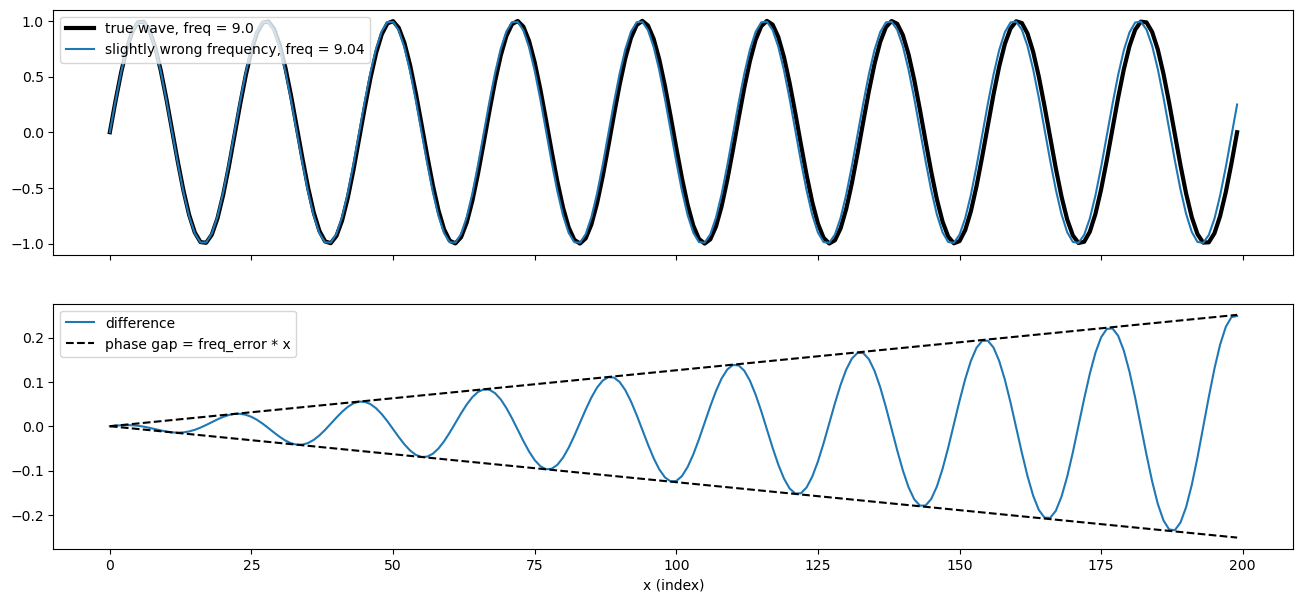

In [19]:
freq, freq_error = 9.0, 0.04

true_wave = torch.sin(freq * coord)
wrong_wave = torch.sin((freq + freq_error) * coord)
phase_gap = freq_error * coord          # grows linearly along x

fig, axs = plt.subplots(2, 1, figsize=(16, 7), sharex=True)

axs[0].plot(true_wave, linewidth=3, color="black", label=f"true wave, freq = {freq}")
axs[0].plot(wrong_wave, label=f"slightly wrong frequency, freq = {freq + freq_error}")
axs[0].legend(loc="upper left")

axs[1].plot(wrong_wave - true_wave, label="difference")
axs[1].plot(phase_gap, "k--", label="phase gap = freq_error * x")
axs[1].plot(-phase_gap, "k--")
axs[1].legend(loc="upper left")
axs[1].set_xlabel("x (index)")

The difference oscillates at the wave's own frequency, inside an envelope (dashed lines) that starts at zero and grows linearly with x. This is the same fan shape as in the difference plot of the generated curves. (For a small gap the envelope is $\Delta f \cdot x$, with x in the units of `coord`, i.e. from 0 to $2\pi$.)

Three remarks:

- **Frequencies 12 and 16 are outside the training range.** With `freq_max = 10` the network never saw a condition above 1 (12 or 16 divided by 10), so it has not learned what a larger condition means and in our runs it falls back to about the highest frequency it knows, roughly 10 (compare the black and colored curves in the centered plot). The curves are completely out of step within the first few cycles, and the difference rises and falls instead of growing smoothly.
- **The flat offset at frequency 1.5 is a side effect of centering, not a model error.** We center each generated curve by subtracting its mean, so its mean is 0. But 1.5 cycles of a sine wave do not average to 0: the extra half cycle is above zero, and the mean of the true wave is about 0.21. The centered curve therefore sits about 0.21 below the true wave everywhere, which you can also see in the centered plot.
- **Why is the frequency slightly off at all?** The network has to turn one number, the condition, into the spacing of the cycles at every point of the curve, and it learns to do this only approximately. A likely reason is a limitation of our design, discussed at the end of this notebook: the position $x$ is not an input to the network.

## Unpack the differences between the simple and attention-based U-Net

Apart from being trained separately, the only difference between **`model_simple`** and **`model_atten`** is the mid block (the bottleneck, at the bottom of the U).

- For **`model_simple`**, the mid block is a conditional residual block, **`ResBlock1D_conditional`**, defined in lines 72–115 of unet_1d.py. In summary it does: convolution → group norm → inject embedding → activation → convolution → group norm → activation → add the block's input back (the residual connection).
- For **`model_atten`**, the mid block is modified in unet_1d_attention.py: the same residual block is followed by **position embedding injection** and **multi-head self-attention**, i.e. convolution → … → residual connection **→ injecting position embedding → multi-head self-attention** (see more details in Lines 29 and 30 unet_1d_attention.py).

The details of the attention mechanism are outside the scope of this tutorial. What matters here is *how far each part of the network can see*.

### The simple U-Net only sees a local window

A convolution looks at only a few neighbouring points (3 here). Stacking layers and downsampling widen this view, but in our simple U-Net each output point is still influenced by only about 60 of the 200 points. This window is called the *receptive field*.

So the simple U-Net effectively draws the curve as overlapping local pieces. Each piece can make a nice local sine wave, but each piece judges the spacing of the cycles by itself locally, and nothing ties the left end of the curve to the right end. Small disagreements between the pieces add up, so the frequency can **wander** along a single curve.

### Attention lets every part see every other part

At the bottleneck the signal has been downsampled to 50 positions, 4 original points apart. Self-attention lets each of these 50 positions look at all the others in a single step, so the whole curve can agree on one frequency. A fixed sinusoidal position encoding is added before attention, so attention also knows how far apart two positions are.

An example from large language models: in "I walk along the river. It is very beautiful. Near the bank, there is a person", whether "bank" means a river bank or a financial institution depends on the word "river", several words earlier. A model that only looks at nearby words can miss this (i.e., ``model_simple``); with attention (``model_atten``), "bank" can look directly at "river".

### Seeing the difference: the phase lag along x (generated by Claude)

To check this, the cell below measures how far each generated curve is ahead of (+) or behind (−) the true wave, in short windows along x. We call this the *phase lag*. If a curve has a constant frequency error $\Delta f$, its phase lag is a straight line that starts at zero, whose slope is $\Delta f$ (with x measured like `coord`, from 0 to $2\pi$). If its frequency wanders, the phase lag bends up and down.

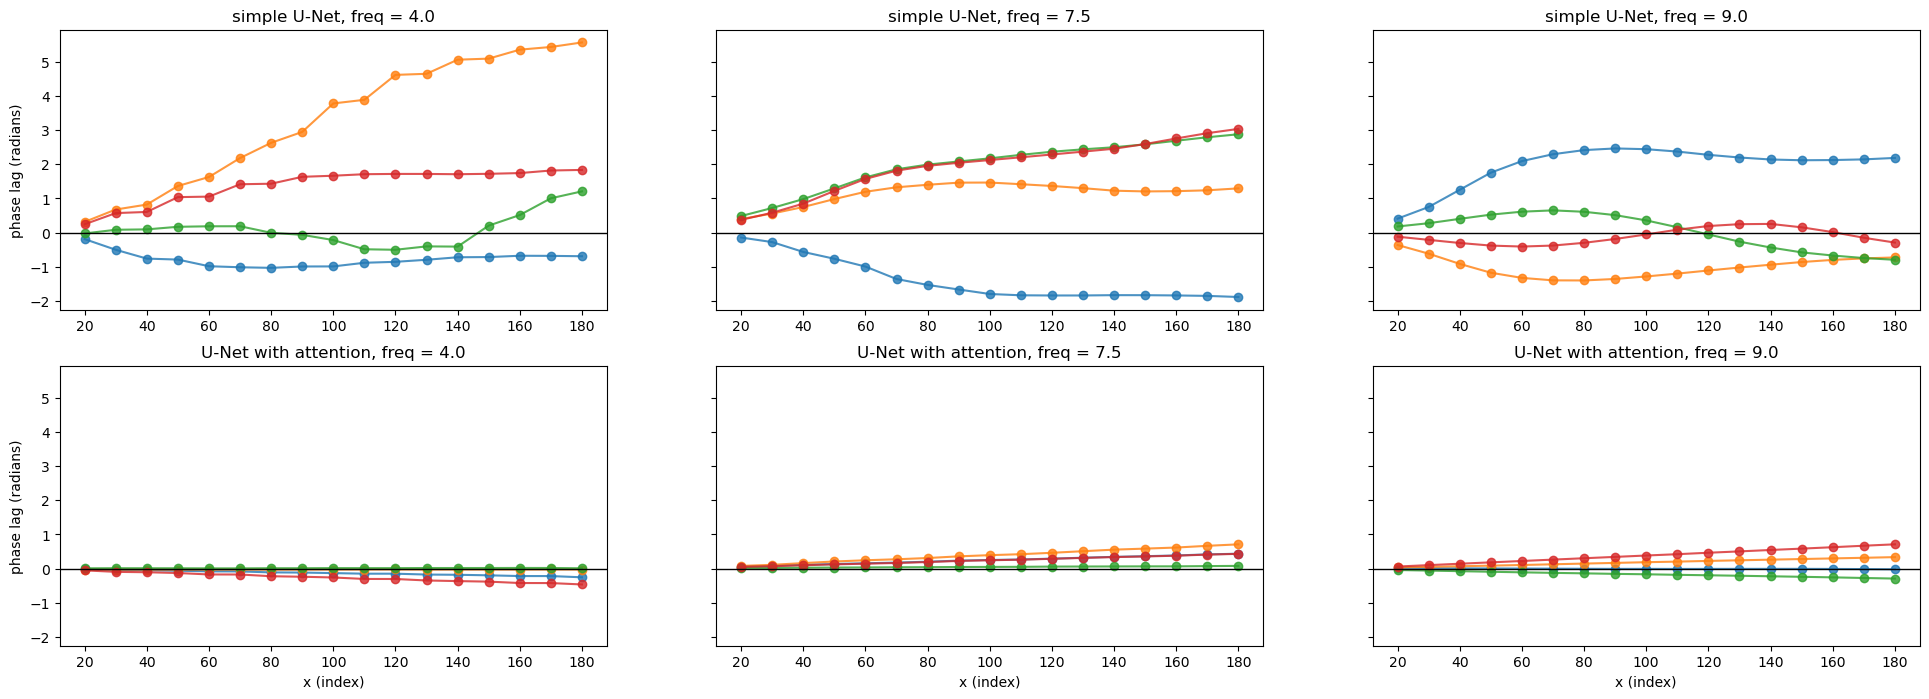

In [20]:
def phase_lag(sample, freq, window=40, step=10):
    """
    How far a generated curve is ahead of (+) or behind (-) sin(freq * x), in radians,
    measured in short windows along x.

    In each window we fit  a + b*sin(freq*x) + c*cos(freq*x)  by least squares; the constant a
    absorbs the random bias, and atan2(c, b) is the phase of the curve in that window.
    """
    centers, lags = [], []
    for start in range(0, len(coord) - window + 1, step):
        x = coord[start:start + window]
        y = sample[start:start + window]
        design = torch.stack([torch.ones_like(x), torch.sin(freq * x), torch.cos(freq * x)], dim=1)
        a, b, c = torch.linalg.lstsq(design, y[:, None]).solution[:, 0]
        centers.append(start + window // 2)
        lags.append(torch.atan2(c, b).item())
    return centers, np.unwrap(lags)


show_freqs = [4.0, 7.5, 9.0]
models = [("simple U-Net", generated_list_simple), ("U-Net with attention", generated_list_atten)]

fig, axs = plt.subplots(2, 3, figsize=(24, 8), sharey=True)

for col, freq in enumerate(show_freqs):
    k = freqs.index(freq)
    for row, (name, generated_list) in enumerate(models):
        ax = axs[row, col]
        for sample in generated_list[k]:
            centers, lags = phase_lag(sample[0].detach().cpu(), freq)
            ax.plot(centers, lags, marker="o", alpha=0.8)
        ax.axhline(0, color="black", linewidth=1)
        ax.set_title(f"{name}, freq = {freq}")

for ax in axs[:, 0]:
    ax.set_ylabel("phase lag (radians)")
for ax in axs[1]:
    ax.set_xlabel("x (index)")

How to read the plot (the curves change from run to run, but the pattern should not):

- **Simple U-Net (top row):** the lines bend, so their slope, the local frequency error, changes along x. Some curves may also be off already at the left end. The frequency wanders along the curve.
- **U-Net with attention (bottom row):** the lines start near zero at the left end and are nearly straight, with small slopes. Each curve has one constant frequency that is slightly off, which is exactly the situation explained in "Why does the difference grow along x?" above.

So both models produce a difference that grows along x, but for different reasons: in the simple U-Net the frequency wanders, while in the U-Net with attention a small, constant frequency error accumulates.

## A limitation of this experiment: the position is not an input

To get the phase of $\sin(f \cdot x)$ right everywhere, the network has to know, at every point, how far that point is from the left end. Yet the position $x$ is not one of the network's inputs:

- The inputs are only $x_t$ (200 values), the time step $t$, and the condition $c$.
- $t$ and $c$ are combined into one embedding vector, which is added **in the same way at every position** (line 108 of unet_1d.py). It says *which* frequency to draw, not *where* on the curve we are.
- A convolution applies the same filter everywhere, so by itself it cannot tell positions apart either.

So the network has to work out where it is indirectly:

- **model_simple** can only use the zero padding at the two ends of the signal. A point more than about 30 points from both ends cannot see either end (its receptive field is about 60 points wide), so it has no direct way of knowing which phase it should be at; it can only follow its neighbours.
- **model_atten** additionally receives a position encoding, but only inside the attention layer at the bottleneck, where neighbouring positions are 4 original points apart.

This makes the task harder than it needs to be. It is a likely reason why the frequency of the simple U-Net wanders, and why the U-Net with attention still has a small frequency error. We have not tested this here.

(Another reason, also not covered here: the frequency of a curve is mostly decided early in generation, while $x_t$ is still very noisy. The later steps largely keep whatever frequency is already visible in $x_t$.)

A natural improvement, which we have **not** tested, is to give the network its position directly, for example as a second input channel that holds `coord`. This is the "spatially aligned condition" from the previous notebook: position $i$ of the extra channel belongs to position $i$ of $x_t$. In our `UNet1D` this needs a small change, because the first convolution would take 2 channels while the output (the predicted noise) must still have 1.

Keep this limitation in mind when reading the results above: the frequency errors in this notebook may partly reflect how we set up the network, not only what diffusion models can do.

## What is intentionally skipped

- **How attention works inside** (queries, keys, values, multiple heads). We only use the fact that every position can look at every other one.
- **A quantitative evaluation.** We judged the models by eye and with the phase-lag plot of a few curves, not by measuring the frequency of many generated curves.
- **Why the frequency is decided early in generation, and why training does not push harder to correct it.** This has to do with how the training loss weights the different noise levels.
- **Fixes that we have not tried here:** giving the network its position as an input, training longer, or strengthening the condition with classifier-free guidance (mentioned in the previous notebook).
- **Random phase** (`random_phase=True`). Without a fixed starting phase at the left end, a frequency error would show up differently.
- **Extrapolation beyond `freq_max`.** We only point out that it fails.

Next we will move on to use diffusino model for parameter estimation